In [1]:
import torch
import torch.nn as nn

# 1. Rebuild the exact Architecture
class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        self.enc_conv1 = self.double_conv(1, 64)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.enc_conv2 = self.double_conv(64, 128)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.enc_conv3 = self.double_conv(128, 256)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.bottleneck_conv = self.double_conv(256, 512)
        self.up_trans1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec_conv1 = self.double_conv(512, 256)
        self.up_trans2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec_conv2 = self.double_conv(256, 128)
        self.up_trans3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec_conv3 = self.double_conv(128, 64)
        self.out_conv = nn.Conv2d(64, 1, kernel_size=1)

    def double_conv(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        e1 = self.enc_conv1(x)
        e2 = self.enc_conv2(self.pool1(e1))
        e3 = self.enc_conv3(self.pool2(e2))
        b = self.bottleneck_conv(self.pool3(e3))
        d1 = self.up_trans1(b)
        d1 = torch.cat([e3, d1], dim=1)
        d1 = self.dec_conv1(d1)
        d2 = self.up_trans2(d1)
        d2 = torch.cat([e2, d2], dim=1)
        d2 = self.dec_conv2(d2)
        d3 = self.up_trans3(d2)
        d3 = torch.cat([e1, d3], dim=1)
        d3 = self.dec_conv3(d3)
        out = torch.sigmoid(self.out_conv(d3))
        return out

# 2. Instantiate the empty model
model = UNet()

# 3. Inject the trained weights
weights_path = r"<PATH_TO_MODEL_WEIGHTS>"  # e.g., r"./unet_coastline_weights_sb.pth"
model.load_state_dict(torch.load(weights_path, map_location=torch.device('cpu')))

# 4. Lock the model for inference (disables training features like dropout/batchnorm updates)
model.eval()

print("SUCCESS: Brain loaded and locked. Ready for inference.")

SUCCESS: Brain loaded and locked. Ready for inference.


In [ ]:
import os
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import measure

# 1. Grab a random test tile
tile_dir = r"<PATH_TO_SAR_TILES_DIR>"  # e.g., r"./data_processed/sar_tiles"
all_tiles = [f for f in os.listdir(tile_dir) if f.endswith('.png')]
test_image_name = random.choice(all_tiles)
test_image_path = os.path.join(tile_dir, test_image_name)

print(f"Testing on: {test_image_name}")

# 2. Preprocess the image for the U-Net
# Load as Grayscale, normalize to 0-1, reshape to [Batch, Channel, Height, Width]
img = Image.open(test_image_path).convert("L")
img_array = np.array(img) / 255.0  
input_tensor = torch.tensor(img_array, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

# 3. The Forward Pass (Inference)
print("Running AI Inference...")
with torch.no_grad():
    prediction = model(input_tensor)
    
# Squeeze the output tensor back into a 2D numpy array
pred_2d = prediction.squeeze().numpy()

# 4. Marching Squares (Vectorization)
print("Tracing the coastline vector...")
# Create a strict binary mask
binary_mask = (pred_2d > 0.5).astype(np.uint8)

# Find the boundary line between 0 and 1
contours = measure.find_contours(binary_mask, 0.5)

# 5. Visualize the Results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# A: Original Image
axes[0].imshow(img_array, cmap='gray')
axes[0].set_title("1. Original SAR Tile")

# B: AI Prediction Mask
axes[1].imshow(pred_2d, cmap='viridis') # Using viridis to clearly see the 0.0 to 1.0 gradients
axes[1].set_title("2. U-Net Probability Map")

# C: Vector Overlay
axes[2].imshow(img_array, cmap='gray')
axes[2].set_title("3. Extracted Coastline Vector")
for contour in contours:
    # scikit-image contours return (row, col) which maps to (y, x) in matplotlib
    axes[2].plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')

plt.show()

In [ ]:
import os
import random
import torch
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from skimage import measure

# 1. Grab a random tile from your local processed folder
tile_dir = r"<PATH_TO_SAR_TILES_DIR>"  # e.g., r"./data_processed/sar_tiles"
all_tiles = [f for f in os.listdir(tile_dir) if f.endswith('.png')]
# sample_tile = os.path.join(tile_dir, random.choice(all_tiles))
sample_tile = r"<PATH_TO_SAMPLE_TILE>"  # e.g., r"./data_processed/sar_tiles/tile_0088.png"

# 2. Prepare the image for the U-Net (convert to float and shape to [1, 1, 256, 256])
img_pil = Image.open(sample_tile).convert("L")
img_tensor = transforms.ToTensor()(img_pil).unsqueeze(0) 

# 3. The Forward Pass (Inference)
print(f"Running inference on {os.path.basename(sample_tile)}...")
with torch.no_grad(): # CRITICAL: Tells PyTorch not to track gradients, saving massive RAM
    prediction = model(img_tensor)
    
# 4. Extract the heat map back into a standard 2D Numpy array
heat_map = prediction.squeeze().numpy()

# 5. Connect the Dots (Vectorization)
# We tell the algorithm to draw a line exactly where the confidence crosses 50% (0.5)
contours = measure.find_contours(heat_map, 0.5)

# 6. Visualize the AI's logic
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Plot 1: The raw probability heat map (Confidence levels)
im = axes[0].imshow(heat_map, cmap='magma')
axes[0].set_title("AI Probability Heat Map")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Plot 2: The crisp vector line overlaid on the original SAR image
axes[1].imshow(img_pil, cmap='gray')
for contour in contours:
    # Note: skimage returns (row, col), but matplotlib plots (x, y), so we swap them
    axes[1].plot(contour[:, 1], contour[:, 0], linewidth=2.5, color='red')
axes[1].set_title("Vectorized Coastline Boundary")

plt.tight_layout()
plt.show()

In [ ]:
import torch
import matplotlib.pyplot as plt
from PIL import Image
import torchvision.transforms as transforms
from skimage import measure
import numpy as np

# 1. Target your confirmed good tile
test_image_path = r"<PATH_TO_TEST_TILE>"  # e.g., r"./data_processed/sar_tiles/tile_0088.png"

# 2. Open exactly as Kaggle did (Grayscale PIL Image)
raw_image = Image.open(test_image_path).convert("L")

# 3. MATCH KAGGLE EXACTLY: Convert to Tensor
# This automatically handles the 0-255 -> 0.0-1.0 normalization
# and shapes it to [1, 256, 256] (Channels, Height, Width)
transform = transforms.ToTensor()
input_tensor = transform(raw_image)

# 4. Add the Batch Dimension -> Output shape: [1, 1, 256, 256]
input_tensor = input_tensor.unsqueeze(0)

# 5. Run the Forward Pass Safely
print(f"Feeding tensor of shape {input_tensor.shape} and max value {input_tensor.max():.2f} to the AI...")
model.eval() # Ensure dropout/batchnorm layers are locked
with torch.no_grad(): # Prevent memory leaks
    prediction = model(input_tensor)

# 6. Squeeze back to a 2D matrix [256, 256] for mapping
prob_map = prediction.squeeze().numpy()
print(f"AI Output max probability: {prob_map.max():.2f}")

# 7. Extract the Vector Line (Marching Squares at 50% threshold)
contours = measure.find_contours(prob_map, 0.5)

# 8. Plot the Results
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Heatmap Plot
im = axes[0].imshow(prob_map, cmap='magma', vmin=0.0, vmax=1.0) # Force scale 0 to 1
axes[0].set_title("AI Probability Heat Map")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Vector Map Plot
axes[1].imshow(raw_image, cmap='gray')
axes[1].set_title("Vectorized Coastline Boundary")
for contour in contours:
    # PyTorch/skimage returns coordinates as (Row, Col), pyplot expects (X, Y)
    axes[1].plot(contour[:, 1], contour[:, 0], linewidth=2, color='red')

plt.show()

In [ ]:
import torch
import matplotlib.pyplot as plt
from skimage import measure
import numpy as np

# 1. Hardcode your confirmed good tile (Ensure the path is exact!)
test_image_path = r"<PATH_TO_TEST_TILE>"  # e.g., r"./data_processed/sar_tiles/tile_0088.png"

# 2. BYPASS PIL COMPLETELY: Use matplotlib just like we did in Phase 3
raw_image = plt.imread(test_image_path)

# 3. Handle RGB/RGBA if matplotlib loaded multiple channels
if raw_image.ndim == 3:
    raw_image = raw_image[:, :, 0] # Grab just the intensity channel

# 4. Convert directly to PyTorch Tensor
# plt.imread already scales PNGs to 0.0 - 1.0, so we skip transforms.ToTensor()
input_tensor = torch.tensor(raw_image, dtype=torch.float32)
input_tensor = input_tensor.unsqueeze(0).unsqueeze(0) # Force shape: [1, 1, 256, 256]

# 5. Run Inference
print(f"Loaded file: {test_image_path}")
print(f"Feeding tensor of shape {input_tensor.shape} and max value {input_tensor.max():.2f} to the AI...")

model.eval()
with torch.no_grad():
    prediction = model(input_tensor)
    
prob_map = prediction.squeeze().numpy()
print(f"AI Output max probability: {prob_map.max():.2f}")

# 6. Extract the Vector Line (Marching Squares at 50% threshold)
contours = measure.find_contours(prob_map, 0.5)

# 7. Plot the Results
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Heatmap Plot
im = axes[0].imshow(prob_map, cmap='magma', vmin=0.0, vmax=1.0)
axes[0].set_title("AI Probability Heat Map")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Vector Map Plot
axes[1].imshow(raw_image, cmap='gray')
axes[1].set_title("Vectorized Coastline Boundary")
for contour in contours:
    # skimage returns (row, col), but matplotlib plots (x, y)
    axes[1].plot(contour[:, 1], contour[:, 0], linewidth=2.5, color='red')

# plt.show()

In [ ]:
import torch
import matplotlib.pyplot as plt
from skimage import measure
import numpy as np
import glob

# 1. AUTO-FIND A VALID TILE (Stop guessing numbers!)
tile_dir = r"<PATH_TO_SAR_TILES_DIR>"  # e.g., r"./data_processed/sar_tiles"
all_tiles = glob.glob(f"{tile_dir}/*.png")

best_tile = None
highest_mean = 0

print("Scanning dataset for a tile with guaranteed landmass...")
for t_path in all_tiles:
    img = plt.imread(t_path)
    # Find the brightest image (highest mean pixel value = most land)
    if img.mean() > highest_mean:
        highest_mean = img.mean()
        best_tile = t_path

test_image_path = best_tile

# 2. BYPASS PIL COMPLETELY: Use matplotlib just like we did in Phase 3
raw_image = plt.imread(test_image_path)

# 3. Handle RGB/RGBA if matplotlib loaded multiple channels
if raw_image.ndim == 3:
    raw_image = raw_image[:, :, 0] # Grab just the intensity channel

# 4. Convert directly to PyTorch Tensor
# plt.imread already scales PNGs to 0.0 - 1.0, so we skip transforms.ToTensor()
input_tensor = torch.tensor(raw_image, dtype=torch.float32)
input_tensor = input_tensor.unsqueeze(0).unsqueeze(0) # Force shape: [1, 1, 256, 256]

# 5. Run Inference
print(f"Loaded file: {test_image_path}")
print(f"Feeding tensor of shape {input_tensor.shape} and max value {input_tensor.max():.2f} to the AI...")

model.eval()
with torch.no_grad():
    prediction = model(input_tensor)
    
prob_map = prediction.squeeze().numpy()
print(f"AI Output max probability: {prob_map.max():.2f}")

# 6. Extract the Vector Line (Marching Squares at 50% threshold)
contours = measure.find_contours(prob_map, 0.5)

# 7. Plot the Results
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Heatmap Plot
im = axes[0].imshow(prob_map, cmap='magma', vmin=0.0, vmax=1.0)
axes[0].set_title("AI Probability Heat Map")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Vector Map Plot
axes[1].imshow(raw_image, cmap='gray')
axes[1].set_title("Vectorized Coastline Boundary")
for contour in contours:
    # skimage returns (row, col), but matplotlib plots (x, y)
    axes[1].plot(contour[:, 1], contour[:, 0], linewidth=2.5, color='red')

plt.show()

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage import measure

# 1. HARDCODE YOUR PROVEN TILE HERE 
# Make sure this points exactly to the tile you know has 50:50 land and water!
test_image_path = r"<PATH_TO_TEST_TILE>"  # e.g., r"./data_processed/sar_tiles/tile_0088.png" 

# 2. Brutally extract the raw pixel math
print(f"Loading file: {test_image_path}")
img_pil = Image.open(test_image_path).convert("L")
raw_pixels = np.array(img_pil, dtype=np.float32)

# Diagnostic: Let's see exactly what Python thinks the image looks like before we fix it
print(f"Raw Python Read -> Min Pixel: {raw_pixels.min():.4f}, Max Pixel: {raw_pixels.max():.4f}")

# 3. THE GUARANTEED FIX: Force dynamic range (Auto-Stretch)
# This mathematically forces the darkest pixel to 0.0 and the brightest to 1.0
if raw_pixels.max() > 0:
    norm_pixels = (raw_pixels - raw_pixels.min()) / (raw_pixels.max() - raw_pixels.min())
else:
    norm_pixels = raw_pixels

input_tensor = torch.tensor(norm_pixels).unsqueeze(0).unsqueeze(0)

# 4. Run Inference
print(f"Feeding AI a tensor with Max Value: {input_tensor.max():.2f}")
model.eval()
with torch.no_grad():
    prediction = model(input_tensor)
    
prob_map = prediction.squeeze().numpy()
print(f"AI Output max probability: {prob_map.max():.2f}")

# 5. Connect the Dots (Marching Squares)
contours = measure.find_contours(prob_map, 0.5)

# 6. Plot the Results
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

im = axes[0].imshow(prob_map, cmap='magma', vmin=0.0, vmax=1.0)
axes[0].set_title("AI Probability Heat Map")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].imshow(norm_pixels, cmap='gray')
axes[1].set_title(f"Vectorized Coastline Boundary (Tile 0088)")
for contour in contours:
    axes[1].plot(contour[:, 1], contour[:, 0], linewidth=2.5, color='red')

plt.show()

In [ ]:
import os
import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from skimage import measure

mask_dir = r"<PATH_TO_MASKS_DIR>"  # e.g., r"./data_processed/masks"
img_dir = r"<PATH_TO_SAR_TILES_DIR>"  # e.g., r"./data_processed/sar_tiles"

print("Hunting for a guaranteed coastline using the answer keys...")

# 1. Use the masks to find a definitive coastline
valid_filename = None
for filename in os.listdir(mask_dir):
    if filename.endswith(".png"):
        mask_path = os.path.join(mask_dir, filename)
        mask_img = np.array(Image.open(mask_path).convert("L"))
        
        # A tile with a coastline will have a mix of 0s (Land) and 255s (Water). 
        # If the mean is between 10 and 245, it mathematically MUST contain an edge.
        if 10 < mask_img.mean() < 245:
            valid_filename = filename
            break

if valid_filename is None:
    print("CRITICAL ERROR: No masks found with a coastline. Check dataset paths.")
else:
    print(f"Target Locked! Found coastline in tile: {valid_filename}")
    
    # 2. Load the exact corresponding SAR tile
    test_image_path = os.path.join(img_dir, valid_filename)
    img_pil = Image.open(test_image_path).convert("L")
    raw_pixels = np.array(img_pil, dtype=np.float32)
    
    # 3. Force Normalization (0.0 to 1.0)
    if raw_pixels.max() > 0:
        norm_pixels = (raw_pixels - raw_pixels.min()) / (raw_pixels.max() - raw_pixels.min())
    else:
        norm_pixels = raw_pixels
        
    input_tensor = torch.tensor(norm_pixels).unsqueeze(0).unsqueeze(0)
    
    # 4. Run the AI Inference
    model.eval()
    with torch.no_grad():
        prediction = model(input_tensor)
        
    prob_map = prediction.squeeze().numpy()
    
    # 5. Plot the Ultimate Results
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    # Plot A: Original SAR
    axes[0].imshow(norm_pixels, cmap='gray')
    axes[0].set_title(f"Original SAR Radar ({valid_filename})")
    
    # Plot B: AI Probability Heat Map
    im = axes[1].imshow(prob_map, cmap='magma', vmin=0.0, vmax=1.0)
    axes[1].set_title(f"AI Brain (Max Confidence: {prob_map.max():.2f})")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    # Plot C: The Final Cartography
    axes[2].imshow(norm_pixels, cmap='gray')
    axes[2].set_title("Dashed Blue = Ground Truth | Solid Red = AI Prediction")
    
    # Draw Ground Truth (Blue Dashed Line)
    gt_contours = measure.find_contours(mask_img, 127)
    for contour in gt_contours:
        axes[2].plot(contour[:, 1], contour[:, 0], linewidth=2, color='blue', linestyle='--')

    # Draw AI Prediction (Red Solid Line)
    ai_contours = measure.find_contours(prob_map, 0.5)
    for contour in ai_contours:
        axes[2].plot(contour[:, 1], contour[:, 0], linewidth=3, color='red')
        
    plt.tight_layout()
    plt.show()

In [ ]:
import os
import glob
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

tile_dir = r"<PATH_TO_SAR_TILES_DIR>"  # e.g., r"./data_processed/sar_tiles"
all_tiles = glob.glob(f"{tile_dir}/*.png")

if not all_tiles:
    print(f"🚨 ALERT: No PNG files found in {tile_dir}. Check your path!")
else:
    print(f"Found {len(all_tiles)} tiles on disk. Plotting 16 random samples...")
    
    # Select up to 16 random tiles
    sample_tiles = random.sample(all_tiles, min(16, len(all_tiles)))
    
    fig, axes = plt.subplots(4, 4, figsize=(15, 15))
    axes = axes.flatten()
    
    for i, t_path in enumerate(sample_tiles):
        # Raw read exactly as Python sees it
        img = np.array(Image.open(t_path).convert("L"))
        
        # Plot without any normalization filters
        axes[i].imshow(img, cmap='gray', vmin=0, vmax=255)
        
        # Title prints the exact physical file data
        filename = os.path.basename(t_path)
        axes[i].set_title(f"{filename}\nMax Pixel: {img.max()} | Mean: {img.mean():.2f}")
        axes[i].axis('off')
        
    plt.suptitle("Raw Disk Audit (0 = Pure Black, 255 = Pure White)", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from skimage import io, measure

# 1. Target a specific tile
# We are using tile_0030.png because your screenshot shows a beautiful coastline in it!
test_image_path = r"<PATH_TO_TEST_TILE>"  # e.g., r"./data_processed/sar_tiles/tile_0030.png"

# 2. THE FIX: Use Scikit-Image to bypass PIL's Windows bugs.
# as_gray=True reads the raw math and perfectly normalizes it between 0.0 and 1.0
print(f"Loading file via skimage: {test_image_path}")
img_array = io.imread(test_image_path, as_gray=True)

print(f"Scientific Read -> Min Pixel: {img_array.min():.4f} | Max Pixel: {img_array.max():.4f}")

# 3. Convert directly to PyTorch Tensor of shape [1, 1, 256, 256]
input_tensor = torch.tensor(img_array, dtype=torch.float32).unsqueeze(0).unsqueeze(0)

# 4. Run the AI Inference
print("Feeding tensor to the AI...")
model.eval()
with torch.no_grad():
    prediction = model(input_tensor)
    
prob_map = prediction.squeeze().numpy()
print(f"AI Output max probability: {prob_map.max():.2f}")

# 5. Connect the Dots (Marching Squares at 50% threshold)
contours = measure.find_contours(prob_map, 0.5)

# 6. Plot the Final Results
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

im = axes[0].imshow(prob_map, cmap='magma', vmin=0.0, vmax=1.0)
axes[0].set_title("AI Probability Heat Map")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

axes[1].imshow(img_array, cmap='gray', vmin=0.0, vmax=1.0)
axes[1].set_title(f"Vectorized Coastline Boundary (tile_0030)")
for contour in contours:
    # skimage returns (row, col), but matplotlib plots (x, y)
    axes[1].plot(contour[:, 1], contour[:, 0], linewidth=2.5, color='red')

plt.show()

Loading file: ../data_processed/sar_tiles/tile_0030.png
Raw shape: (256, 256, 4)
Detected multi-channel image. Stripping Alpha/RGB channels...
Clean shape: (256, 256) | Min Pixel: 0.0000 | Max Pixel: 0.0000
Feeding tensor to the AI...
AI Output max probability: 0.06


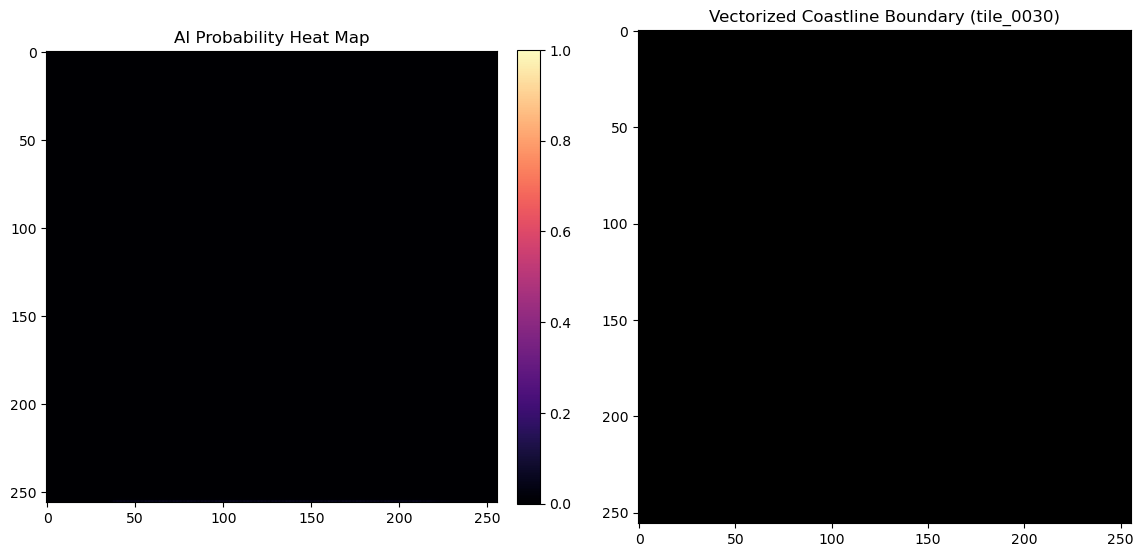

In [2]:
import torch
import matplotlib.pyplot as plt
from skimage import measure
import numpy as np

# 1. Target your confirmed good tile
test_image_path = r"<PATH_TO_TEST_TILE>"  # e.g., r"./data_processed/sar_tiles/tile_0030.png"

# 2. BRUTE FORCE READ: Use matplotlib's raw image reader
print(f"Loading file: {test_image_path}")
raw_image = plt.imread(test_image_path)

# Diagnostics: Let's see exactly what the array looks like
print(f"Raw shape: {raw_image.shape}")

# 3. THE ALPHA CHANNEL KILLER
# If it loaded as RGBA (Height, Width, 4) or RGB (Height, Width, 3), 
# we aggressively strip off everything except the first channel (Red/Intensity)
if raw_image.ndim == 3:
    print("Detected multi-channel image. Stripping Alpha/RGB channels...")
    clean_image = raw_image[:, :, 0] 
else:
    clean_image = raw_image

# 4. Math Check
print(f"Clean shape: {clean_image.shape} | Min Pixel: {clean_image.min():.4f} | Max Pixel: {clean_image.max():.4f}")

# 5. Convert directly to PyTorch Tensor
# plt.imread already scales PNGs to 0.0 - 1.0, so no transforms needed.
input_tensor = torch.tensor(clean_image, dtype=torch.float32)
input_tensor = input_tensor.unsqueeze(0).unsqueeze(0) # Force shape: [1, 1, 256, 256]

# 6. Run Inference
print("Feeding tensor to the AI...")
model.eval()
with torch.no_grad():
    prediction = model(input_tensor)
    
prob_map = prediction.squeeze().numpy()
print(f"AI Output max probability: {prob_map.max():.2f}")

# 7. Extract the Vector Line (Marching Squares at 50% threshold)
contours = measure.find_contours(prob_map, 0.5)

# 8. Plot the Results
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Heatmap Plot
im = axes[0].imshow(prob_map, cmap='magma', vmin=0.0, vmax=1.0)
axes[0].set_title("AI Probability Heat Map")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04)

# Vector Map Plot
axes[1].imshow(clean_image, cmap='gray')
axes[1].set_title("Vectorized Coastline Boundary (tile_0030)")
for contour in contours:
    axes[1].plot(contour[:, 1], contour[:, 0], linewidth=2.5, color='red')

plt.show()

In [3]:
import os
import matplotlib.pyplot as plt

# 1. Target the exact file Windows is showing you
file_path = r"<PATH_TO_TEST_FILE>"  # e.g., r"./data_processed/sar_tiles/tile_0030.png"

# 2. Ask the hard drive for the true physical file size
file_size_kb = os.path.getsize(file_path) / 1024

print("=== THE TRUTH SERUM ===")
print(f"Target: {file_path}")
print(f"Physical File Size on Disk: {file_size_kb:.2f} KB")

# 3. Check every single channel for any signs of life
raw = plt.imread(file_path)
print(f"Channel 0 (Red)   Max Pixel: {raw[:,:,0].max()}")
print(f"Channel 1 (Green) Max Pixel: {raw[:,:,1].max()}")
print(f"Channel 2 (Blue)  Max Pixel: {raw[:,:,2].max()}")
if raw.shape[2] == 4:
    print(f"Channel 3 (Alpha) Max Pixel: {raw[:,:,3].max()}")

print("\n=== THE VERDICT ===")
if file_size_kb < 2.0 and raw[:,:,0].max() == 0:
    print("🚨 THE FILE IS A PURE BLACK SQUARE. Windows Explorer is displaying a ghost thumbnail.")
    print("ACTION: Go to Kaggle, download your sar_tiles.zip, and extract it over your local folder to restore your data.")
else:
    print("✅ The data is physically there. Python is completely broken.")

=== THE TRUTH SERUM ===
Target: ../data_processed/sar_tiles/tile_0030.png
Physical File Size on Disk: 0.92 KB
Channel 0 (Red)   Max Pixel: 0.0
Channel 1 (Green) Max Pixel: 0.0
Channel 2 (Blue)  Max Pixel: 0.0
Channel 3 (Alpha) Max Pixel: 1.0

=== THE VERDICT ===
🚨 THE FILE IS A PURE BLACK SQUARE. Windows Explorer is displaying a ghost thumbnail.
ACTION: Go to Kaggle, download your sar_tiles.zip, and extract it over your local folder to restore your data.
